# 02 · Aprendizaje supervisado: predecir el nivel de tráfico
**TráficoIA · Proyecto Final, versión 3 · Semana 2 (sábado 21 de noviembre)**

Equipo N.º 3 · Integrantes: Cielo, Salvador, Alexander, Javier.

**Pregunta:** dadas la hora, el día de la semana, la temperatura, la lluvia y si es festivo, ¿el tráfico será **bajo, medio o alto**?

**Método (y por qué):**
1. Los niveles se definen con terciles del volumen, **calculados solo con entrenamiento**, para que la prueba no influya en la definición de las clases.
2. Separación 80 % entrenamiento / 20 % prueba.
3. Se comparan cuatro algoritmos (árbol, Random Forest, KNN y regresión logística) más un **modelo base** que siempre responde la clase más frecuente. Si un modelo no supera al base, no aprendió nada.
4. Cada modelo ajusta sus hiperparámetros con **validación cruzada de 5 particiones dentro de entrenamiento**. El mejor modelo se elige por F1 macro de validación cruzada, **nunca mirando la prueba**.
5. La prueba se usa una sola vez, para reportar el resultado final.

> **Antes de ejecutar:** haber descargado los datos (`python src/descargar_datos.py --tabular`). Este cuaderno tarda unos minutos por la búsqueda de hiperparámetros.

In [1]:
import sys, warnings
from pathlib import Path

# Permite importar src/ aunque el cuaderno se ejecute desde notebooks/
RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config, supervisado

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
config.FIGURAS.mkdir(parents=True, exist_ok=True)

def guardar(nombre):
    plt.tight_layout()
    plt.savefig(config.FIGURAS / f"{nombre}.png", dpi=130, bbox_inches="tight")

print("Raíz del proyecto:", RAIZ)

Raíz del proyecto: C:\Users\cielo\Downloads\proyecto_ia_semana1\proyecto_ia\proyecto-ia-traficoia


## 1. Datos, variable objetivo y separación

In [2]:
df = supervisado.cargar_datos_modelado()
print(f"{len(df):,} horas | {df['date_time'].min()}  ->  {df['date_time'].max()}")

part = supervisado.dividir(df)
print(f"Entrenamiento: {len(part.X_train):,} filas | Prueba: {len(part.X_test):,} filas")
print("Variables de entrada:", part.features)
print("Cortes de nivel (calculados SOLO con entrenamiento): "
      "bajo <= {:.0f} < medio <= {:.0f} < alto  (vehículos por hora)".format(*part.cortes))

pd.DataFrame({"entrenamiento": part.y_train.value_counts(normalize=True),
              "prueba": part.y_test.value_counts(normalize=True)}).reindex(config.NIVELES).round(3)

40,575 horas | 2012-10-02 09:00:00  ->  2018-09-30 23:00:00
Entrenamiento: 32,460 filas | Prueba: 8,115 filas
Variables de entrada: ['hora', 'dia_semana', 'temp_c', 'rain_1h', 'festivo_dia']
Cortes de nivel (calculados SOLO con entrenamiento): bajo <= 2265 < medio <= 4595 < alto  (vehículos por hora)


,entrenamiento,prueba
bajo,0.333,0.330
medio,0.333,0.334
alto,0.333,0.336


Interpretación: las tres clases quedan casi equilibradas (≈ 1/3 cada una) porque los niveles se definieron con terciles calculados solo con entrenamiento: bajo ≤ 2265, medio ≤ 4595 y alto por encima (vehículos por hora). En entrenamiento cada clase tiene 33.3 % y en prueba 33.0 %, 33.4 % y 33.6 %, así que la prueba conserva la misma distribución (diferencias menores a 0.4 puntos). Un modelo que siempre responda la misma clase obtendría ≈ 0.33 de exactitud; ese es el piso que hay que superar.

## 2. Comparar algoritmos con validación cruzada
Para cada modelo se prueba una rejilla pequeña de hiperparámetros con 5 particiones. La tabla muestra el mejor de cada uno:

* `f1_macro_cv`: rendimiento en datos que el modelo no vio durante cada ajuste (promedio de las 5 particiones) y su desviación.
* `brecha_sobreajuste`: F1 de entrenamiento menos F1 de validación. Una brecha grande indica que el modelo memoriza.

In [3]:
resultados = supervisado.buscar_mejores(part)      # tarda 1 a 3 minutos
tabla = supervisado.tabla_cv(resultados)
tabla.round(3)

,modelo,mejores_parametros,exactitud_cv,f1_macro_cv,f1_macro_cv_desv,f1_macro_entrenamiento,brecha_sobreajuste
0,Base (clase más frecuente),{},0.333,0.167,0.000,0.167,0.000
1,Árbol de decisión,"{'max_depth': 12, 'min_samples_leaf': 30}",0.899,0.899,0.004,0.903,0.004
2,Random Forest,"{'max_depth': None, 'min_samples_leaf': 5}",0.900,0.900,0.004,0.920,0.019
3,KNN,{'n_neighbors': 15},0.887,0.887,0.002,0.901,0.014
4,Regresión logística,{'C': 1},0.610,0.607,0.007,0.608,0.001


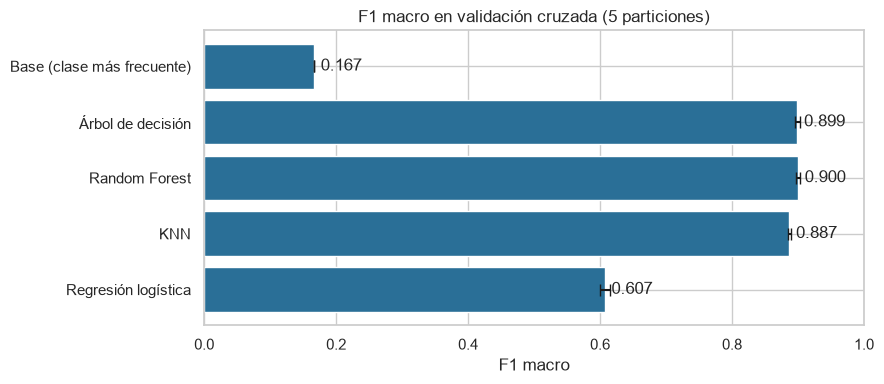

In [4]:
sin_base = tabla[tabla["modelo"] != supervisado.BASE]
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(tabla["modelo"], tabla["f1_macro_cv"], xerr=tabla["f1_macro_cv_desv"], color="#2a6f97", capsize=4)
ax.set(title="F1 macro en validación cruzada (5 particiones)", xlabel="F1 macro", xlim=(0, 1))
ax.invert_yaxis()
for i, v in enumerate(tabla["f1_macro_cv"]):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center")
guardar("sup_comparacion_cv")
plt.show()

Interpretación: Random Forest queda primero (F1 macro 0.900), seguido por el árbol de decisión (0.899), KNN (0.887) y la regresión logística (0.607); el modelo base obtiene 0.167. La diferencia entre Random Forest y el árbol es de 0.001, menor que la desviación entre particiones (0.004), por lo que no se puede afirmar que uno sea mejor que el otro. KNN queda unos 0.013 abajo, algo mayor que la desviación. La regresión logística queda muy atrás porque la relación entre hora y tráfico no es lineal (hay dos picos al día) y un modelo lineal no la captura.

## 3. Resultado en el conjunto de prueba (se mira una sola vez)

In [5]:
tabla_prueba, predicciones = supervisado.evaluar_en_prueba(resultados, part)
comparativa = (tabla.drop(columns="mejores_parametros")
                    .merge(tabla_prueba, on="modelo")
                    .set_index("modelo"))
comparativa[["exactitud_cv", "f1_macro_cv", "exactitud_prueba", "f1_macro_prueba", "brecha_sobreajuste"]].round(3)

,exactitud_cv,f1_macro_cv,exactitud_prueba,f1_macro_prueba,brecha_sobreajuste
modelo,,,,,
Base (clase más frecuente),0.333,0.167,0.330,0.166,0.000
Árbol de decisión,0.899,0.899,0.898,0.898,0.004
Random Forest,0.900,0.900,0.899,0.899,0.019
KNN,0.887,0.887,0.887,0.887,0.014
Regresión logística,0.610,0.607,0.618,0.616,0.001


Interpretación: los valores en prueba son casi idénticos a los de validación cruzada (Random Forest 0.899 frente a 0.900; árbol 0.898 frente a 0.899; KNN 0.887 en ambos). No hay señal de sobreajuste ni de fuga de información: la validación cruzada fue una buena estimación del rendimiento real.

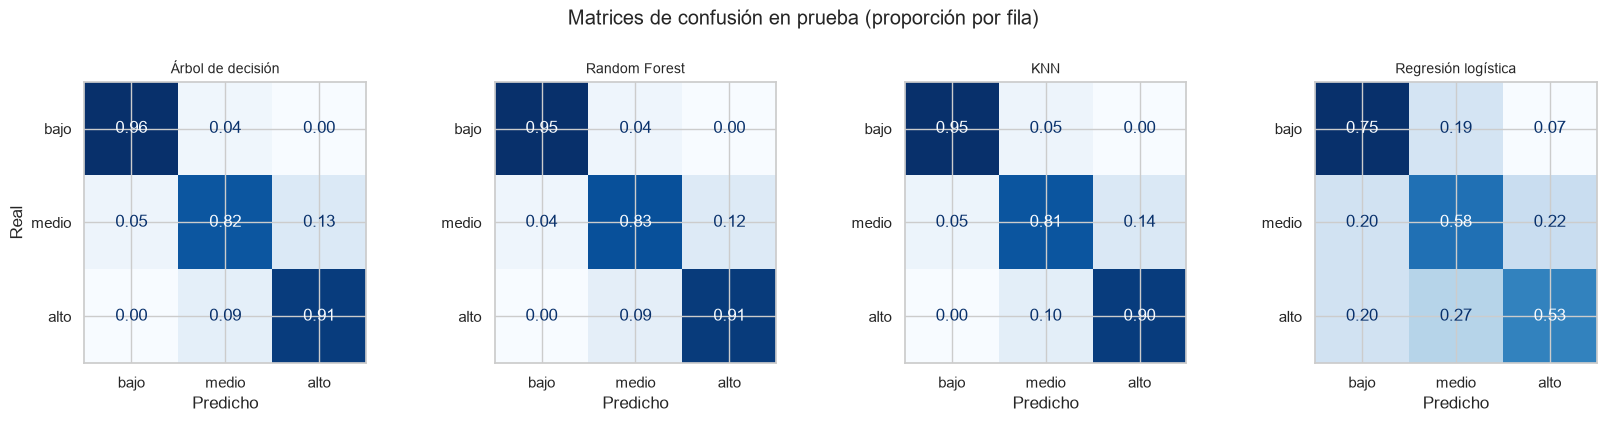

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

modelos_mostrar = [m for m in comparativa.index if m != supervisado.BASE]
fig, ejes = plt.subplots(1, len(modelos_mostrar), figsize=(4.2 * len(modelos_mostrar), 4))
for ax, m in zip(np.atleast_1d(ejes), modelos_mostrar):
    ConfusionMatrixDisplay.from_predictions(part.y_test, predicciones[m], labels=config.NIVELES,
                                            normalize="true", cmap="Blues", ax=ax, colorbar=False,
                                            values_format=".2f")
    ax.set_title(m, fontsize=10)
    ax.set_xlabel("Predicho"); ax.set_ylabel("Real" if ax is np.atleast_1d(ejes)[0] else "")
fig.suptitle("Matrices de confusión en prueba (proporción por fila)", y=1.02)
guardar("sup_matrices_confusion")
plt.show()

## 4. Elegir el mejor modelo
La elección se hace con la **validación cruzada** (entrenamiento), no con la prueba.

In [7]:
candidatos = tabla[tabla["modelo"] != supervisado.BASE]
mejor = candidatos.loc[candidatos["f1_macro_cv"].idxmax(), "modelo"]
print("Mejor modelo por F1 macro de validación cruzada:", mejor)
print("Hiperparámetros:", resultados[mejor].best_params_)
print()
print(classification_report(part.y_test, predicciones[mejor], labels=config.NIVELES, digits=3))

Mejor modelo por F1 macro de validación cruzada: Random Forest
Hiperparámetros: {'m__max_depth': None, 'm__min_samples_leaf': 5}

              precision    recall  f1-score   support

        bajo      0.957     0.954     0.955      2681
       medio      0.862     0.835     0.848      2710
        alto      0.879     0.909     0.894      2724

    accuracy                          0.899      8115
   macro avg      0.899     0.899     0.899      8115
weighted avg      0.899     0.899     0.899      8115



Interpretación: elegimos Random Forest porque tuvo el mayor F1 macro en validación cruzada (0.900), criterio fijado antes de mirar la prueba. Está en empate técnico con el árbol de decisión (0.899), pero un bosque promedia muchos árboles y es más estable ante cambios en los datos; el árbol sería más fácil de explicar. Por clase, "bajo" se predice mejor (F1 0.955), "alto" queda en 0.894 y "medio" es la más difícil (0.848), lo que es lógico porque está entre las otras dos.

## 5. Sobreajuste
El árbol de decisión es el caso clásico: sin límite de profundidad memoriza el entrenamiento. La curva muestra cómo cambia el F1 al dejarlo crecer.

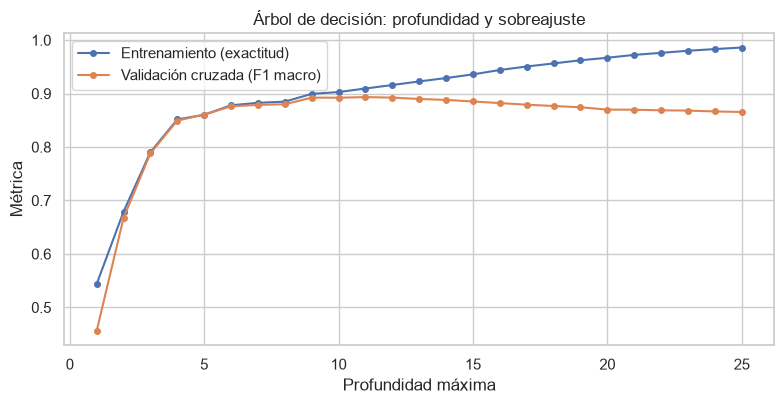

Mejor profundidad por validación cruzada: 11


In [8]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier

kf = StratifiedKFold(5, shuffle=True, random_state=config.SEMILLA)
filas = []
for d in range(1, 26):
    arbol = Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("m", DecisionTreeClassifier(max_depth=d, random_state=config.SEMILLA))])
    f_cv = cross_val_score(arbol, part.X_train, part.y_train, cv=kf, scoring="f1_macro", n_jobs=-1).mean()
    f_tr = arbol.fit(part.X_train, part.y_train).score(part.X_train, part.y_train)
    filas.append({"profundidad": d, "entrenamiento": f_tr, "validacion_cruzada": f_cv})
curva = pd.DataFrame(filas)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(curva["profundidad"], curva["entrenamiento"], marker="o", ms=4, label="Entrenamiento (exactitud)")
ax.plot(curva["profundidad"], curva["validacion_cruzada"], marker="o", ms=4, label="Validación cruzada (F1 macro)")
ax.set(title="Árbol de decisión: profundidad y sobreajuste", xlabel="Profundidad máxima", ylabel="Métrica")
ax.legend()
guardar("sup_curva_profundidad")
plt.show()
print("Mejor profundidad por validación cruzada:", int(curva.loc[curva['validacion_cruzada'].idxmax(), 'profundidad']))

Interpretación: el F1 de validación sube hasta una profundidad cercana a 10 (el mejor valor por validación cruzada fue 11, ≈ 0.89) y después empieza a bajar, hasta ≈ 0.865 con profundidad 25. En cambio, la exactitud de entrenamiento sigue subiendo hasta ≈ 0.98. Esa separación creciente entre las dos curvas es el sobreajuste: el árbol profundo memoriza el entrenamiento. Por eso el árbol de la tabla usa una profundidad máxima limitada (12) y un mínimo de 30 muestras por hoja.

## 6. Análisis de errores: ¿a qué horas y en qué condiciones se confunden los niveles?
Esta es la interpretación que pide la especificación. Se analiza el modelo elegido sobre el conjunto de prueba.

In [9]:
err = part.X_test.copy()
err["hora"] = err["hora"].astype(int)
err["dia_semana"] = err["dia_semana"].astype(int)
err["real"] = part.y_test
err["predicho"] = predicciones[mejor]
err["error"] = err["real"] != err["predicho"]

print(f"Tasa de error global: {err['error'].mean():.1%}\n")
print("Confusiones (filas = real, columnas = predicho):")
print(pd.crosstab(err["real"], err["predicho"]).reindex(index=config.NIVELES, columns=config.NIVELES))

orden = {n: i for i, n in enumerate(config.NIVELES)}
distancia = (err["real"].map(orden) - err["predicho"].map(orden)).abs()
print(f"\nDe los errores, {(distancia[err['error']] == 1).mean():.1%} son entre niveles vecinos "
      f"(bajo-medio o medio-alto) y {(distancia[err['error']] == 2).mean():.1%} son bajo<->alto.")

Tasa de error global: 10.1%

Confusiones (filas = real, columnas = predicho):
predicho  bajo  medio  alto
real                       
bajo      2557    117     7
medio      115   2262   333
alto         1    246  2477

De los errores, 99.0% son entre niveles vecinos (bajo-medio o medio-alto) y 1.0% son bajo<->alto.


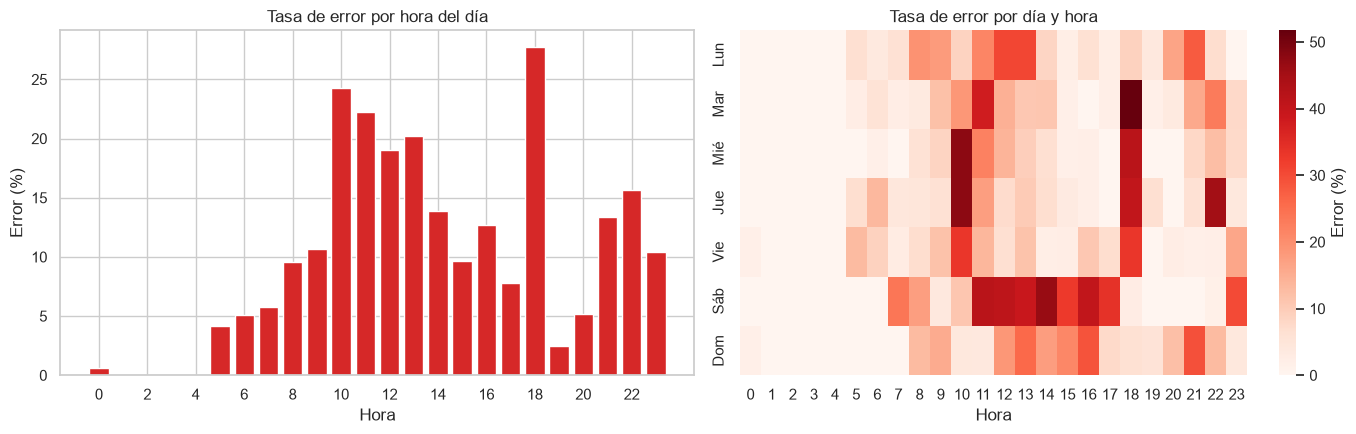

Las 5 horas con más error:
hora
18    27.7
10    24.3
11    22.3
13    20.2
12    19.1


In [10]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
por_hora = err.groupby("hora")["error"].mean()
ejes[0].bar(por_hora.index, por_hora.values * 100, color="#d62828")
ejes[0].set(title="Tasa de error por hora del día", xlabel="Hora", ylabel="Error (%)", xticks=range(0, 24, 2))

mapa = err.pivot_table(index="dia_semana", columns="hora", values="error", aggfunc="mean") * 100
mapa.index = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
sns.heatmap(mapa, cmap="Reds", ax=ejes[1], cbar_kws={"label": "Error (%)"})
ejes[1].set(title="Tasa de error por día y hora", xlabel="Hora", ylabel="")
guardar("sup_errores_hora")
plt.show()

print("Las 5 horas con más error:")
print((por_hora.sort_values(ascending=False).head(5) * 100).round(1).to_string())

In [11]:
condiciones = pd.DataFrame({
    "Festivo": err.groupby(err["festivo_dia"].astype(bool))["error"].mean().rename({False: "No", True: "Sí"}),
    "Llueve (>0 mm)": err.groupby(err["rain_1h"] > 0)["error"].mean().rename({False: "No", True: "Sí"}),
    "Fin de semana": err.groupby(err["dia_semana"] >= 5)["error"].mean().rename({False: "No", True: "Sí"}),
}).T
(condiciones * 100).round(1).rename_axis("Condición").add_prefix("Error % si = ")

,Error % si = No,Error % si = Sí
Condición,,
Festivo,10.0,14.6
Llueve (>0 mm),10.2,8.5
Fin de semana,9.1,12.4


Interpretación:
* Horas de los errores: la tasa de error global es 10.1 %. Se concentran en las horas de transición y de mucho movimiento: 18 h (27.7 %), 10 h (24.3 %), 11 h (22.3 %), 13 h (20.2 %) y 12 h (19.1 %). De noche (0 a 5 h) casi no hay errores. En el mapa de calor se ve además que los sábados entre las 10 y las 14 h el error es alto.
* Tipo de error: el 99.0 % de los errores son entre niveles vecinos (bajo-medio o medio-alto) y solo 1.0 % salta de bajo a alto. El modelo falla por los bordes de las clases, donde el volumen está cerca de un corte, y no por entender mal el patrón.
* Festivo, lluvia y fin de semana: el error es mayor en festivos (14.6 % frente a 10.0 %) y en fin de semana (12.4 % frente a 9.1 %), probablemente porque hay menos ejemplos de festivos y porque el patrón del fin de semana es menos regular. La lluvia no aumenta el error (8.5 % con lluvia frente a 10.2 % sin ella).

## 7. Importancia de las variables

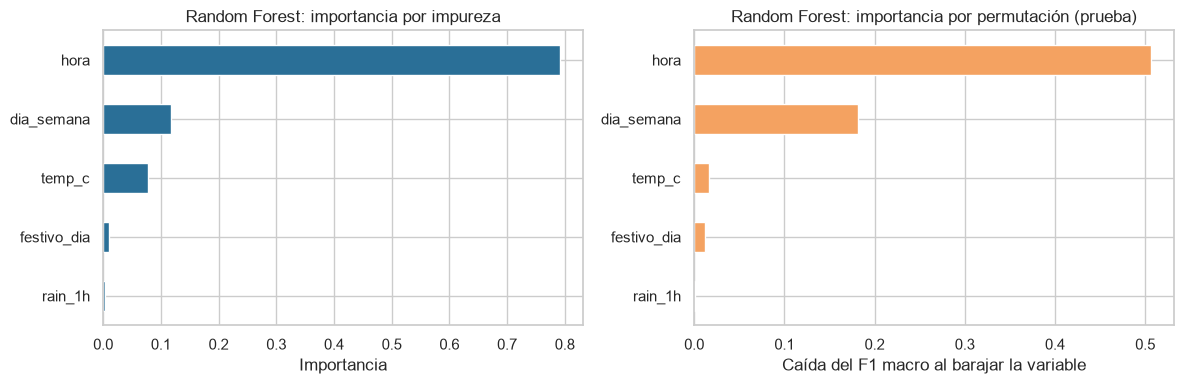

In [12]:
from sklearn.inspection import permutation_importance

rf = resultados["Random Forest"].best_estimator_
imp_rf = pd.Series(rf.named_steps["m"].feature_importances_, index=part.features).sort_values()

muestra = part.X_test.sample(min(5000, len(part.X_test)), random_state=config.SEMILLA)
perm = permutation_importance(resultados[mejor].best_estimator_, muestra, part.y_test.loc[muestra.index],
                              scoring="f1_macro", n_repeats=5, random_state=config.SEMILLA, n_jobs=-1)
imp_perm = pd.Series(perm.importances_mean, index=part.features).sort_values()

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
imp_rf.plot.barh(ax=ejes[0], color="#2a6f97")
ejes[0].set(title="Random Forest: importancia por impureza", xlabel="Importancia")
imp_perm.plot.barh(ax=ejes[1], color="#f4a261")
ejes[1].set(title=f"{mejor}: importancia por permutación (prueba)", xlabel="Caída del F1 macro al barajar la variable")
guardar("sup_importancia_variables")
plt.show()

Interpretación: la variable que domina es la hora, con mucha diferencia, y en segundo lugar queda el día de la semana. Esto coincide con lo esperado: el patrón horario (picos de mañana y tarde) explica casi todo el volumen. La temperatura, la lluvia y el festivo aportan poco. La importancia por permutación, calculada sobre prueba, confirma el orden que da la importancia por impureza.

## 8. Dos experimentos para validar el resultado
**a) Variables cíclicas.** La hora 23 y la hora 0 están pegadas, pero para el modelo son 23 unidades de distancia. Se prueba codificar hora y día con seno y coseno (afecta sobre todo a KNN).

**b) Validación temporal.** Una separación aleatoria deja horas vecinas (casi iguales) en entrenamiento y en prueba, lo que **favorece** al modelo. Entrenar con el pasado y probar con el futuro es más realista.

In [13]:
df_ciclicas = supervisado.dividir(df, features=supervisado.FEATURES_CICLICAS)
df_temporal = supervisado.dividir(df, temporal=True)

filas = []
for m in modelos_mostrar:
    base_r = comparativa.loc[m, "f1_macro_prueba"]
    f_cic = supervisado.reentrenar_en(resultados, m, df_ciclicas)["f1_macro"]
    f_tmp = supervisado.reentrenar_en(resultados, m, df_temporal)["f1_macro"]
    filas.append({"modelo": m, "F1 aleatoria (base)": base_r, "F1 con variables cíclicas": f_cic,
                  "F1 validación temporal": f_tmp, "cambio temporal": f_tmp - base_r})
experimentos = pd.DataFrame(filas).set_index("modelo")
experimentos.round(3)

,F1 aleatoria (base),F1 con variables cíclicas,F1 validación temporal,cambio temporal
modelo,,,,
Árbol de decisión,0.898,0.895,0.902,0.004
Random Forest,0.899,0.898,0.902,0.003
KNN,0.887,0.890,0.892,0.005
Regresión logística,0.616,0.763,0.599,-0.017


Interpretación: las variables cíclicas (seno y coseno de hora y día) mejoran a KNN de 0.887 a 0.890, una mejora pequeña. El efecto grande se ve en la regresión logística, que sube de 0.616 a 0.763, aunque sigue lejos de los modelos de árboles. Árbol y Random Forest casi no cambian (0.898 → 0.895 y 0.899 → 0.898). Con validación temporal el F1 no baja: Random Forest pasa de 0.899 a 0.902, el árbol de 0.898 a 0.902 y KNN de 0.887 a 0.892. Una caída pequeña (aquí no hay caída) indica que el patrón horario es estable en el tiempo y que la separación aleatoria no era optimista. En el informe final se reportan ambos números.

## 9. Guardar el modelo y probarlo

In [14]:
metricas = {
    "f1_macro_cv": float(comparativa.loc[mejor, "f1_macro_cv"]),
    "exactitud_cv": float(comparativa.loc[mejor, "exactitud_cv"]),
    "f1_macro_prueba": float(comparativa.loc[mejor, "f1_macro_prueba"]),
    "exactitud_prueba": float(comparativa.loc[mejor, "exactitud_prueba"]),
    "f1_macro_temporal": float(experimentos.loc[mejor, "F1 validación temporal"]),
}
paquete = supervisado.crear_paquete(resultados, mejor, part, metricas)
ruta = supervisado.guardar_modelo(paquete)
print("Modelo guardado en:", ruta)

salida = config.RAIZ / "reports" / "tabla_comparativa_supervisado.csv"
comparativa.round(4).to_csv(salida)
print("Tabla comparativa guardada en:", salida)

Modelo guardado en: C:\Users\cielo\Downloads\proyecto_ia_semana1\proyecto_ia\proyecto-ia-traficoia\models\mejor_modelo_supervisado.joblib
Tabla comparativa guardada en: C:\Users\cielo\Downloads\proyecto_ia_semana1\proyecto_ia\proyecto-ia-traficoia\reports\tabla_comparativa_supervisado.csv


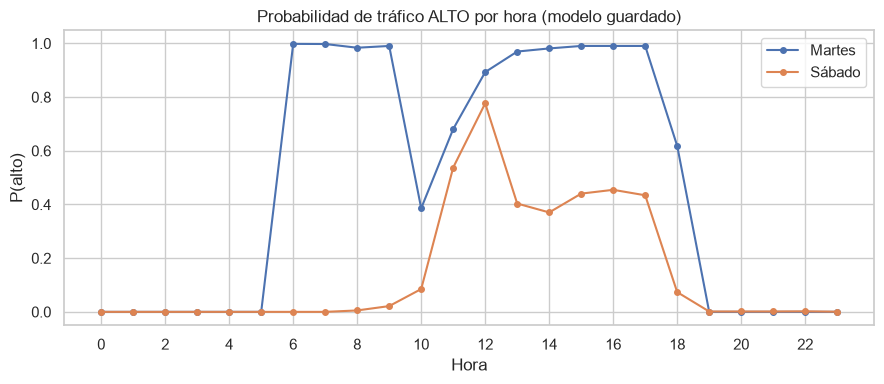

hora,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
dia,,,,,,,,,,,,,,,,,,,,,,,,
Martes,bajo,bajo,bajo,bajo,bajo,medio,alto,alto,alto,alto,medio,alto,alto,alto,alto,alto,alto,alto,alto,medio,medio,medio,bajo,bajo
Sábado,bajo,bajo,bajo,bajo,bajo,bajo,bajo,bajo,medio,medio,medio,alto,alto,medio,medio,medio,medio,medio,medio,medio,medio,medio,medio,bajo


In [15]:
# Recargar y predecir: así lo usará la app de la semana 4
paquete = supervisado.cargar_modelo()
filas = []
for dia, nombre_dia in [(1, "Martes"), (5, "Sábado")]:
    for h in range(24):
        r = supervisado.predecir_nivel(paquete, hora=h, dia_semana=dia)
        filas.append({"dia": nombre_dia, "hora": h, "nivel": r["nivel"], "p_alto": r["probabilidades"]["alto"]})
prev = pd.DataFrame(filas)

fig, ax = plt.subplots(figsize=(9, 4))
for nombre_dia, g in prev.groupby("dia"):
    ax.plot(g["hora"], g["p_alto"], marker="o", ms=4, label=nombre_dia)
ax.set(title="Probabilidad de tráfico ALTO por hora (modelo guardado)", xlabel="Hora", ylabel="P(alto)",
       xticks=range(0, 24, 2))
ax.legend()
guardar("sup_prediccion_por_hora")
plt.show()

prev.pivot(index="hora", columns="dia", values="nivel").T

Interpretación: las curvas tienen sentido. El martes el tráfico pasa de bajo (0 a 4 h) a medio (5 h) y alto desde las 6 h, con el pico de la mañana; el sábado se mantiene bajo hasta las 7 h y sube más tarde y con menos intensidad (medio de 8 a 10 h). Eso coincide con lo que se espera de un día laboral frente a un fin de semana, así que el modelo guardado se puede usar en la app de la semana 4.

## Conclusiones del módulo supervisado
1. El mejor modelo es Random Forest, con F1 macro de 0.900 (± 0.004) en validación cruzada y 0.899 en prueba (exactitud 0.899).
2. Supera ampliamente al modelo base (F1 macro 0.167 en CV y 0.166 en prueba) y a la regresión logística (0.607 en CV y 0.616 en prueba) por casi 0.3 puntos, porque la relación entre hora y tráfico no es lineal y la regresión logística no la capta. Frente al árbol de decisión (0.899) hay empate técnico.
3. Los niveles se confunden sobre todo en las horas de transición y de mucho movimiento (18 h con 27.7 % de error, 10 h con 24.3 % y 11 h con 22.3 %). La tasa de error global es 10.1 % y el 99 % de los errores son entre niveles vecinos; "medio" es la clase más difícil (F1 0.848).
4. La hora es la variable que más importa, seguida del día de la semana; la temperatura, la lluvia y el festivo aportan poco. La lluvia no aumentó el error (8.5 % frente a 10.2 %), mientras que festivo (14.6 %) y fin de semana (12.4 %) sí lo aumentaron.
5. Con validación temporal el F1 de Random Forest no cayó (0.899 → 0.902), lo que indica que el patrón horario es estable. Las variables cíclicas ayudaron poco a KNN (0.887 → 0.890) y mucho a la regresión logística (0.616 → 0.763), aunque esta sigue muy por debajo de los árboles.
6. Limitaciones: los datos vienen de una sola autopista, el clima está simplificado a temperatura y lluvia, y hay pocas horas festivas. Mejoras posibles: incluir el volumen de las horas anteriores, más variables de clima y datos de otras vías, y probar otros modelos como el boosting.